# 05 · Does the effect last? Weekly curve, survival analysis of engagement, ROI correction

Read with: [`11_survival_decay_and_roi.md`](../docs/learn/11_survival_decay_and_roi.md).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from tierlift.config import REPO_ROOT, load_config
from tierlift.simulate import SimulatedData
cfg = load_config()
DATA, RESULTS, FIGS = REPO_ROOT / "data", REPO_ROOT / "results", REPO_ROOT / "reports" / "figures"
assert DATA.exists(), "run `make all` (or `tierlift run-all`) first: the notebooks read data/ and results/"
data = SimulatedData.load(DATA)
e, truth = data.experiment, data.truth.set_index("client_id")
primary, control = cfg.analysis.primary_contrast
def fig(name): display(Image(filename=str(FIGS / name), width=900))
print(f"seed {cfg.seed}, {len(e):,} clients, cells {cfg.experiment.cells}")

seed 13, 5,000 clients, cells {'holdout': 0.3, 'nudge': 0.3, 'incentive': 0.4}


## 1. The weekly incentive-vs-holdout gap over 39 weeks

{'initial_effect_pct': 0.0370707518331102, 'weekly_decay': 0.02363998882112306, 'weekly_decay_se': 0.004511074203824744, 'half_life_weeks': 28.973005113923712, 'r2': 0.44089678609530236}


,effect_pct,se_pct,ci_low,ci_high
week,,,,
1,0.0436,0.0248,-0.0050,0.0921
2,0.0191,0.0261,-0.0320,0.0702
3,0.0398,0.0246,-0.0084,0.0880
4,0.0120,0.0259,-0.0387,0.0627
5,0.0217,0.0262,-0.0297,0.0730


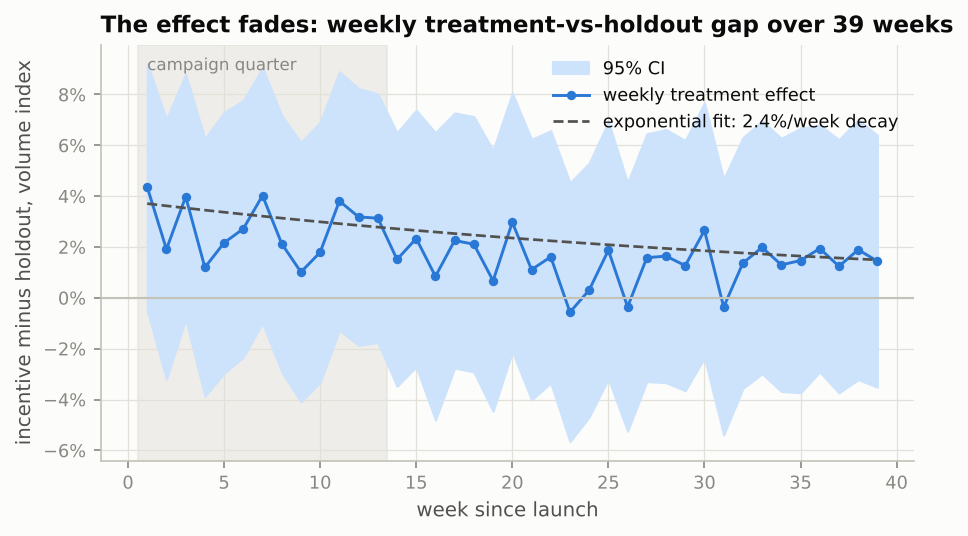

In [2]:
from tierlift.durability.survival import weekly_effect_curve, fit_exponential_decay, kaplan_meier, weekly_hazard, cox_model, cox_table
pre_weekly = data.pre_weekly.groupby("client_id")["volume"].mean()
curve = weekly_effect_curve(data.weekly, data.assignment, primary, control, pre_weekly)
decay = fit_exponential_decay(curve); print(decay)
display(curve.head()); fig("11_weekly_effect.png")

## 2. Engagement survival: Kaplan–Meier and the weekly hazard

pooled weekly hazard 0.0193 ± 0.0004 (planted 0.02)


,week,survival,se,n_at_risk
0,1.0000,0.9806,0.0023,3497
1,2.0000,0.9628,0.0032,3429
2,3.0000,0.9460,0.0038,3367
3,4.0000,0.9288,0.0043,3308
4,5.0000,0.9088,0.0049,3248
5,6.0000,0.8870,0.0054,3178
6,7.0000,0.8679,0.0057,3102
7,8.0000,0.8513,0.0060,3035


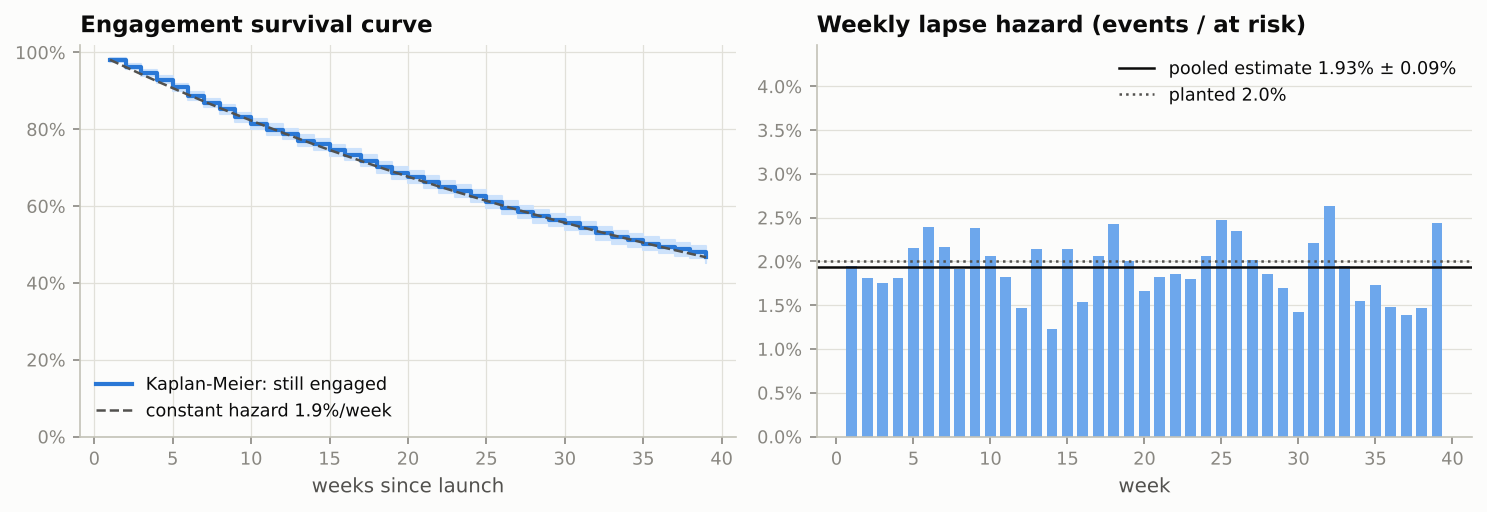

In [3]:
treated = e[e["cell"] != control]
km = kaplan_meier(treated["lapse_week"].to_numpy(), treated["lapsed"].to_numpy())
hz = weekly_hazard(treated["lapse_week"].to_numpy(), treated["lapsed"].to_numpy())
print(f"pooled weekly hazard {hz.attrs['pooled_hazard']:.4f} ± {hz.attrs['pooled_hazard_se']:.4f} (planted {cfg.truth.base_weekly_hazard})")
display(km.head(8)); fig("12_survival.png")

## 3. Who lapses fastest? Cox proportional hazards

,log_hr,hazard_ratio,se,p_value
covariate,,,,
has_account_manager,-0.1444,0.8656,0.0249,0.0000
api_share,0.1092,1.1154,0.0289,0.0002
engagement_z,-0.1955,0.8224,0.0284,0.0000
tenure_months,-0.0217,0.9786,0.0231,0.3473


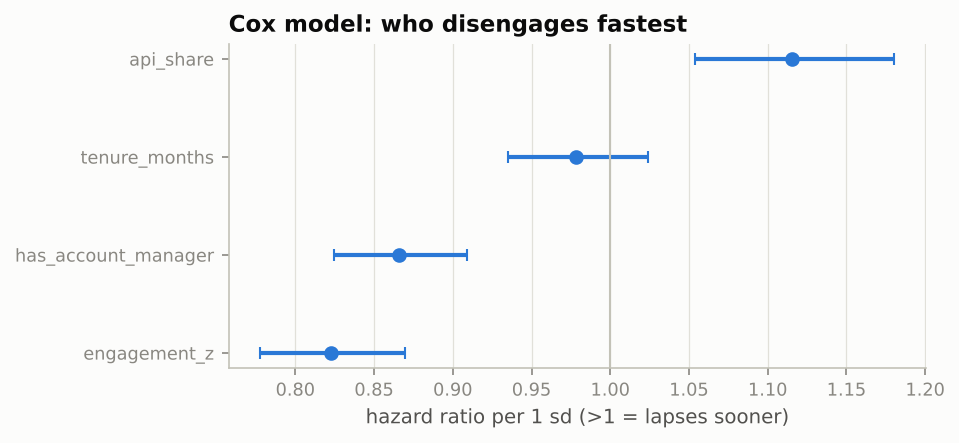

In [4]:
COX = ["has_account_manager", "api_share", "engagement_z", "tenure_months"]
display(cox_table(cox_model(treated, "lapse_week", "lapsed", COX), COX)); fig("13_cox_hazard_ratios.png")

## 4. The ROI correction

m(13) = 0.892, m(52) = 0.634, naive/true = 1.406


,volume_gain,rate_cost,net,benefit_overstatement_pct,net_overstatement_pct
Naive (flat annualisation),"25,814,297.9482","-10,029,124.4418","15,785,173.5064",0.4064,0.8958
Decay-adjusted,"18,355,321.3681","-10,029,124.4418","8,326,196.9264",0.0000,0.0000


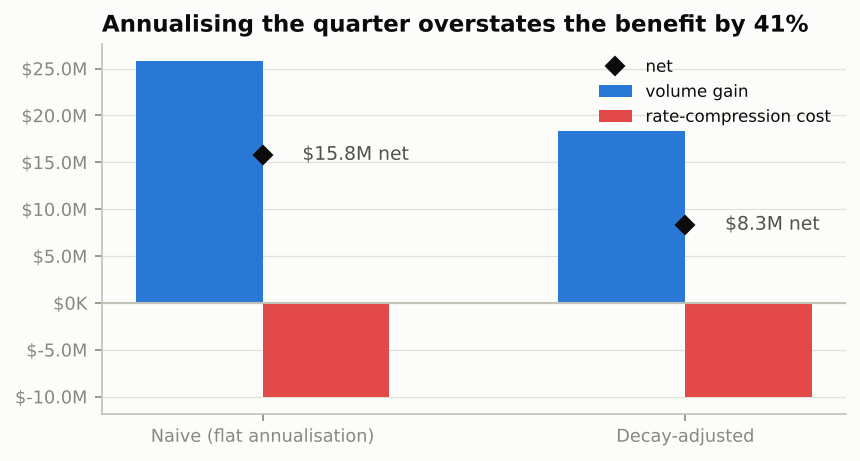

In [5]:
from tierlift.durability.roi import roi_projection, decay_multiplier
h = hz.attrs["pooled_hazard"]
print(f"m(13) = {decay_multiplier(h, 13):.3f}, m(52) = {decay_multiplier(h, 52):.3f}, naive/true = {decay_multiplier(h, 13) / decay_multiplier(h, 52):.3f}")
display(pd.read_csv(RESULTS / "roi_projection.csv", index_col=0)); fig("14_roi_projection.png")

## Check your understanding

1. Recompute the naive/true ratio with h = 1% and h = 4%. Sketch the relationship.
2. The rate-compression cost is *not* decayed in the projection. Give the business reason, and say what would have to be true for it to decay too.
3. Censoring: 39 weeks of follow-up, hazard ≈ 2%/week. Roughly what share of treated clients are still engaged (censored) at the end? Check against the KM table.